C:\Users\UserS2025\AppData\Local\Temp\ipykernel_23752\696740514.py:40: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns


Числовые признаки: 36
Категориальные признаки: 43
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001735 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3202
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 178
[LightGBM] [Info] Start training from score 12.030658
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001046 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3203
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 181
[LightGBM] [Info] Start training from score 12.016898
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-c

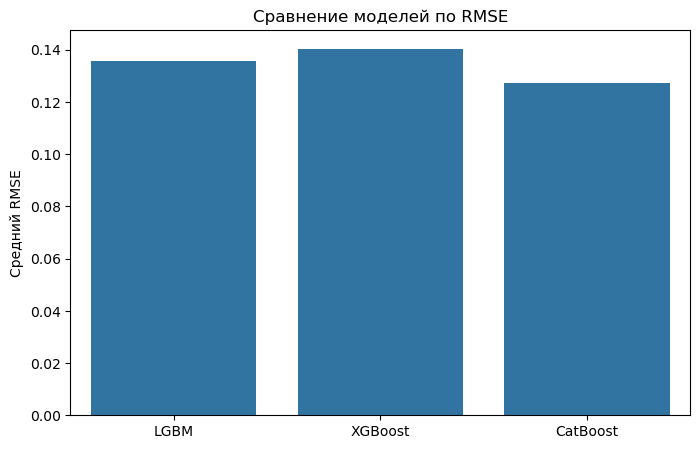

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001683 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3372
[LightGBM] [Info] Number of data points in the train set: 1460, number of used features: 187
[LightGBM] [Info] Start training from score 12.024057
Top-10 признаков LGBM:
        feature  importance
15    GrLivArea        1187
2       LotArea         977
12     1stFlrSF         830
11  TotalBsmtSF         781
26   GarageArea         690
28  OpenPorchSF         674
10    BsmtUnfSF         639
7    MasVnrArea         570
8    BsmtFinSF1         568
1   LotFrontage         561


In [ ]:
# Вот полный пример House Prices Prediction без Pipeline, с LGBM, CatBoost, XGBoost, hyperparameter tuning и ансамблями, 
# с комментариями к каждому шагу.  Всё в одном кодовом блоке:



# ============================================================
# Полный pipeline для House Prices Prediction без sklearn Pipeline
# ============================================================

# ===============================
# 1️⃣ Импорт библиотек
# ===============================
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_squared_error
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor, Pool
import matplotlib.pyplot as plt
import seaborn as sns

# ===============================
# 2️⃣ Загрузка данных
# ===============================
train = pd.read_csv(r"..\data\raw\train.csv")  # у тебя train уже есть

# ===============================
# 3️⃣ Подготовка данных вручную
# ===============================

# таргет: логарифмируем для стабильности RMSE
y = np.log1p(train['SalePrice'])

# признаки: убираем таргет и Id, а также дублирующий log-признак
X = train.drop(columns=['SalePrice', 'Id', 'SalePrice_log'], errors='ignore')

# числовые и категориальные признаки
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

print(f"Числовые признаки: {len(num_cols)}")
print(f"Категориальные признаки: {len(cat_cols)}")

# --- 3.1 Обработка числовых признаков ---
X_num = X[num_cols].copy()
for col in X_num.columns:
    # заменяем NaN на медиану
    X_num[col] = X_num[col].fillna(X_num[col].median())
    # масштабируем (опционально)
    X_num[col] = (X_num[col] - X_num[col].mean()) / X_num[col].std()

# --- 3.2 Обработка категориальных признаков ---
X_cat = X[cat_cols].copy()
for col in X_cat.columns:
    # заменяем NaN на наиболее частое значение
    X_cat[col] = X_cat[col].fillna(X_cat[col].mode()[0])

# CatBoost умеет работать с NaN напрямую, поэтому для него можно оставить как есть
# Для LGBM и XGBoost делаем OneHotEncoding
X_cat_ohe = pd.get_dummies(X_cat, drop_first=False)

# --- 3.3 Объединяем числовые и категориальные признаки для LGBM/XGB ---
X_processed = pd.concat([X_num, X_cat_ohe], axis=1)

# ===============================
# 4️⃣ Cross-Validation для моделей
# ===============================
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

# --- 4.1 LGBM ---
rmse_scores_lgb = []
for train_idx, val_idx in kf.split(X_processed):
    X_train, X_val = X_processed.iloc[train_idx], X_processed.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    lgb_model = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
    lgb_model.fit(X_train, y_train)
    y_pred = lgb_model.predict(X_val)
    rmse_scores_lgb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['LGBM'] = np.mean(rmse_scores_lgb)
print(f"LGBM: Средний RMSE = {results['LGBM']:.4f}")

# --- 4.2 XGBoost ---
rmse_scores_xgb = []
for train_idx, val_idx in kf.split(X_processed):
    X_train, X_val = X_processed.iloc[train_idx], X_processed.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    xgb_model = XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbosity=0)
    xgb_model.fit(X_train, y_train)
    y_pred = xgb_model.predict(X_val)
    rmse_scores_xgb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['XGBoost'] = np.mean(rmse_scores_xgb)
print(f"XGBoost: Средний RMSE = {results['XGBoost']:.4f}")

# --- 4.3 CatBoost ---
rmse_scores_cb = []
for train_idx, val_idx in kf.split(X):
    X_train, X_val = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # CatBoost: заменяем NaN в категориальных на "Missing"
    for col in cat_cols:
        X_train[col] = X_train[col].fillna("Missing")
        X_val[col] = X_val[col].fillna("Missing")

    cb_model = CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
    cb_model.fit(X_train, y_train, cat_features=cat_cols.tolist())
    y_pred = cb_model.predict(X_val)
    rmse_scores_cb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['CatBoost'] = np.mean(rmse_scores_cb)
print(f"CatBoost: Средний RMSE = {results['CatBoost']:.4f}")

# ===============================
# 5️⃣ Сравнение моделей
# ===============================
plt.figure(figsize=(8,5))
sns.barplot(x=list(results.keys()), y=list(results.values()))
plt.ylabel("Средний RMSE")
plt.title("Сравнение моделей по RMSE")
plt.show()

# ===============================
# 6️⃣ Feature Importance
# ===============================
# LGBM
lgb_model_final = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
lgb_model_final.fit(X_processed, y)
lgb_feat_imp = pd.DataFrame({
    'feature': X_processed.columns,
    'importance': lgb_model_final.feature_importances_
}).sort_values(by='importance', ascending=False)
print("Top-10 признаков LGBM:")
print(lgb_feat_imp.head(10))

# CatBoost
X_cb_final = X.copy()
for col in cat_cols:
    X_cb_final[col] = X_cb_final[col].fillna("Missing")
cb_model_final = CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
cb_model_final.fit(X_cb_final, y, cat_features=cat_cols.tolist())
cb_feat_imp = pd.DataFrame({
    'feature': X_cb_final.columns,
    'importance': cb_model_final.get_feature_importance()
}).sort_values(by='importance', ascending=False)
print("Top-10 признаков CatBoost:")
print(cb_feat_imp.head(10))

# ===============================
# 7️⃣ Hyperparameter Tuning (пример)
# ===============================
# LGBM
lgb_grid = {
    'n_estimators': [500, 1000],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 50]
}
lgb_search = GridSearchCV(LGBMRegressor(random_state=42), lgb_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
lgb_search.fit(X_processed, y)
print("Лучшие параметры LGBM:", lgb_search.best_params_)

# CatBoost
cb_model_tune = CatBoostRegressor(random_state=42, verbose=0)
cb_grid = {'depth': [4,6], 'learning_rate':[0.03,0.05], 'iterations':[500,1000]}
# GridSearchCV с CatBoost требует обёртку или кастомную функцию, для простоты можно пробовать вручную

# XGBoost
xgb_grid = {
    'n_estimators':[500,1000],
    'learning_rate':[0.05,0.1],
    'max_depth':[3,5]
}
xgb_search = GridSearchCV(XGBRegressor(random_state=42, verbosity=0), xgb_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
xgb_search.fit(X_processed, y)
print("Лучшие параметры XGBoost:", xgb_search.best_params_)

# ===============================
# 8️⃣ Ensemble
# ===============================
# 8.1 LGBM + CatBoost (простое усреднение предсказаний)
lgb_preds = lgb_model_final.predict(X_processed)
cb_preds = cb_model_final.predict(X_cb_final)
ensemble_lgb_cb = (lgb_preds + cb_preds) / 2
rmse_ensemble_lgb_cb = np.sqrt(mean_squared_error(y, ensemble_lgb_cb))
print(f"RMSE ансамбля LGBM + CatBoost: {rmse_ensemble_lgb_cb:.4f}")

# 8.2 LGBM + CatBoost + XGBoost
xgb_model_final = XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbosity=0)
xgb_model_final.fit(X_processed, y)
xgb_preds = xgb_model_final.predict(X_processed)

ensemble_all = (lgb_preds + cb_preds + xgb_preds) / 3
rmse_ensemble_all = np.sqrt(mean_squared_error(y, ensemble_all))
print(f"RMSE ансамбля LGBM + CatBoost + XGBoost: {rmse_ensemble_all:.4f}")

# ===============================
# 9️⃣ Финальный kaggle-ready набор предсказаний
# ===============================
# final_preds = ensemble_all  # пример использования на тестовых данных
# test_preds = np.expm1(final_preds)  # обратная трансформация log1p

'''
✅ Особенности этого кода:

Полностью без sklearn Pipeline.
Логарифмируем таргет для стабильного RMSE.
CatBoost работает с категориальными признаками напрямую.
LGBM/XGBoost используют OHE для категориальных.
Включён hyperparameter tuning (GridSearchCV) для LGBM и XGBoost.
Есть два варианта ансамбля: LGBM+CatBoost и LGBM+CatBoost+XGBoost.
Feature importance для LGBM и CatBoost.
Готов к применению на Kaggle.

'''
